[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Dilru1/dtw-to-attention/blob/main/notebooks/03_dtw_in_ml_models.ipynb)

In [ ]:
# Setup: run this cell first (installs missing packages when running in Google Colab)
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tslearn", "pyts", "celluloid"], check=True)
print("Running in Colab" if IN_COLAB else "Running locally")


## TP3 - Using DTW and Soft-DTW in classical ML models

## Integrating Alignment Methods into Machine Learning Models

While **Labs 1 and 2** focused on the mechanics of time-series alignment and barycenter computation, this lab embeds those ideas into standard **machine learning frameworks**—specifically **K-Nearest Neighbors (KNN)** and **Support Vector Machines (SVM)**—to tackle time-series classification tasks. A key challenge in time-series classification is that **Euclidean distance** is often an inadequate similarity measure. Because it compares values at identical timestamps ($t_i$ to $t_i$), it is highly sensitive to:

- **Temporal shifts**: signals that start earlier or later  
- **Temporal warping**: signals that evolve at different speeds  

**Dynamic Time Warping (DTW)** addresses this limitation by computing an optimal *non-linear alignment* between two sequences.  
By incorporating DTW as a distance measure (or indirectly as a kernel), machine learning models become **invariant to temporal distortions**, focusing on shape rather than exact timing.


### A. K-Nearest Neighbors (KNN) with DTW

In a standard **1-NN classifier**, a test sequence $x_{test}$ is assigned the label of the closest training sequence:
$$
y_{pred} = \text{label}\left(\arg\min_i \; \text{dist}(x_{test}, x_i)\right)
$$

In this lab, the Euclidean distance is replaced with the **DTW distance**:
$$
\text{DTW}(x, y) =
\min_{\pi \in \mathcal{A}(x, y)} \sum_{(i,j) \in \pi} \|x_i - y_j\|^2
$$

where $\pi$ denotes an alignment path.

This modification allows the 1-NN classifier to correctly match sequences that are *structurally similar* but misaligned in time.


### B. Support Vector Machines (SVM) with Soft-DTW Kernels

SVMs rely on a **kernel function** $K(x, y)$ that measures similarity between samples.  
However, standard DTW is **not a valid kernel**, as it does not always satisfy the Mercer condition (positive semi-definiteness).

To overcome this, we use **Soft-DTW**, a smooth and differentiable relaxation of DTW:

$$
\text{soft-DTW}_\gamma(x, y)
= -\gamma \log \sum_{\pi \in \mathcal{A}(x, y)}
\exp\left(
-\frac{1}{\gamma}
\sum_{(i,j)\in\pi} \|x_i - y_j\|^2
\right)
$$

Based on Soft-DTW, the **Global Alignment Kernel (GAK)** is defined as:

$$
K_{GAK}(x, y)
=
\exp\left(
-\frac{1}{\sigma^2}\,\text{soft-DTW}_\gamma(x, y)
\right)
$$

Unlike standard DTW, GAK aggregates **all possible alignment paths**, weighting them by their quality.  
This results in a **robust similarity measure**, particularly effective for noisy or time-warped signals.




---

### Exercise 1: 1-NN Classification

- **Goal**: Compare classification accuracy between:
  - 1-NN with Euclidean distance  
  - 1-NN with DTW distance  

- **Key Insight**:  
  DTW typically yields significantly better performance on datasets where *signal shape* is more important than exact timing (e.g., the **GunPoint** dataset).


Classification task using the "Trace" dataset (available in tslearn with UCR_UEA_datasets)
Better to scale the timeseries first with a scaler available in tslearn for instance

Compute the accuracy of the 4 following 1NN algorithm:
 - with euclidean distance
 - with DTW
 - with DTW and a Sakoe-Chiba mask
 - with soft-DTW 

For this, you can create a generic 1NN function and then only modify the distance used inside

Compare the results of these 4 algorithms in terms of accuracy and computing time
Show a few series for which 1NN-euclidean fails to classify them but DTW and/or soft-DTW succeed.



---

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from tslearn.datasets import UCR_UEA_datasets
from tslearn.preprocessing import TimeSeriesScalerMinMax
from tslearn.neighbors import KNeighborsTimeSeriesClassifier
from sklearn.metrics import accuracy_score

# 1. Load and Scale the Trace dataset
X_train, y_train, X_test, y_test = UCR_UEA_datasets().load_dataset("Trace")
scaler = TimeSeriesScalerMinMax()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [1]:
# 2. Define the metrics to evaluate
metrics = [
    {"name": "Euclidean", "metric": "euclidean", "params": {}},
    {"name": "DTW", "metric": "dtw", "params": {}},
    {"name": "DTW (Sakoe-Chiba)", "metric": "dtw", "params": {"global_constraint": "sakoe_chiba", "sakoe_chiba_radius": 5}},
    {"name": "Soft-DTW", "metric": "softdtw", "params": {"gamma": 1.0}}
]

results = {}

# 3. Training and Evaluation Loop
for m in metrics:
    start_time = time.time()
    
    # Initialize and fit the 1-NN classifier
    knn = KNeighborsTimeSeriesClassifier(n_neighbors=1, 
                                           metric=m["metric"], 
                                           metric_params=m["params"])
    knn.fit(X_train, y_train)
    
    # Predict
    y_pred = knn.predict(X_test)
    
    elapsed = time.time() - start_time
    acc = accuracy_score(y_test, y_pred)
    
    results[m["name"]] = {"accuracy": acc, "time": elapsed, "predictions": y_pred}
    print(f"{m['name']:<20} | Accuracy: {acc:.4f} | Time: {elapsed:.2f}s")

Euclidean            | Accuracy: 1.0000 | Time: 0.55s
DTW                  | Accuracy: 1.0000 | Time: 24.14s
DTW (Sakoe-Chiba)    | Accuracy: 1.0000 | Time: 19.76s
Soft-DTW             | Accuracy: 1.0000 | Time: 83.03s


---

#### Exercise 2: Classification with SVM

Use the "GunPoint" dataset and compare the accuracy of the following SVMs:
 - linear SVM
 - rbf kernel
 - GAK kernel 

In [ ]:
import time
from tslearn.datasets import UCR_UEA_datasets
from tslearn.preprocessing import TimeSeriesScalerMinMax
from tslearn.svm import TimeSeriesSVC
from sklearn.metrics import accuracy_score

# 1. Load and Scale the GunPoint dataset
# GunPoint involves tracking the hand movement of actors either drawing a gun or pointing a finger.
X_train, y_train, X_test, y_test = UCR_UEA_datasets().load_dataset("GunPoint")
scaler = TimeSeriesScalerMinMax()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 2. Define SVM models with different kernels
models = [
    {"name": "Linear SVM", "kernel": "linear", "params": {}},
    {"name": "RBF Kernel", "kernel": "rbf", "params": {"gamma": "auto"}},
    {"name": "GAK Kernel", "kernel": "gak", "params": {"gamma": "auto", "n_jobs": -1}} # Try 'gamma' here
]
results_svm = {}

# 3. Train and Evaluate
for m in models:
    start_time = time.time()
    
    # TimeSeriesSVC handles both standard and specialized time-series kernels
    clf = TimeSeriesSVC(kernel=m["kernel"], **m["params"])
    clf.fit(X_train, y_train)
    
    y_pred = clf.predict(X_test)
    elapsed = time.time() - start_time
    acc = accuracy_score(y_test, y_pred)
    
    results_svm[m["name"]] = {"accuracy": acc, "time": elapsed}
    print(f"{m['name']:<15} | Accuracy: {acc:.4f} | Time: {elapsed:.2f}s")



    

Linear SVM      | Accuracy: 0.8067 | Time: 0.48s
RBF Kernel      | Accuracy: 0.5000 | Time: 0.46s
GAK Kernel      | Accuracy: 0.7200 | Time: 15.61s


---

#### Exercise 3 : Euclidean k-means VS DTW k-means

On the "Trace" dataset (train + test), compare (visually) the outputs of euclidean and DTW k-means. Choose a number of clusters that seem adapted to these time series

Running Euclidean K-Means...
Running DTW K-Means (this may take a moment)...


/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/sklearn/utils/deprecation.py:95: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)


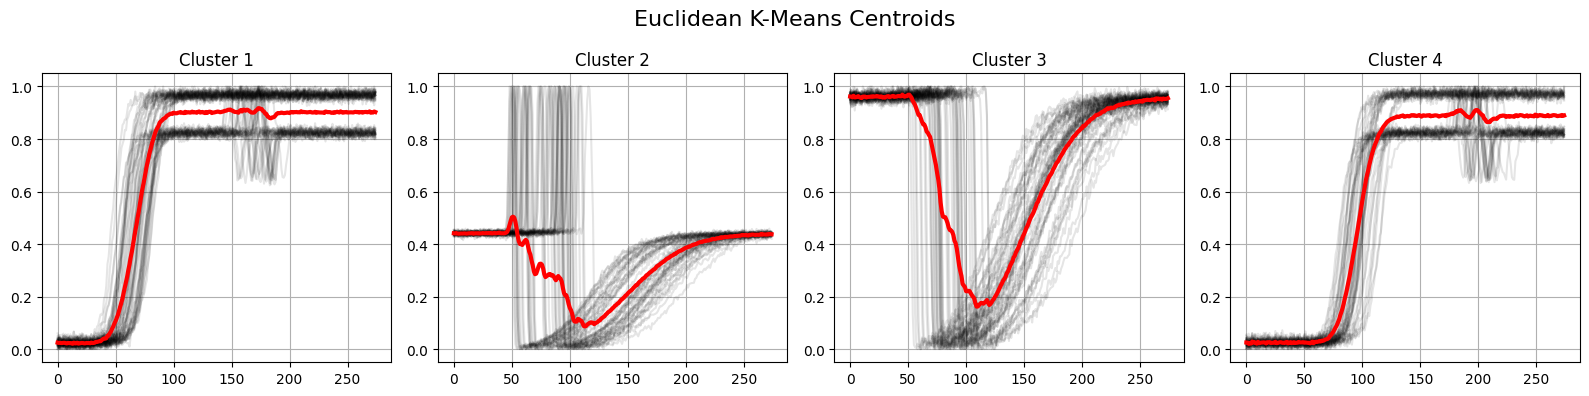

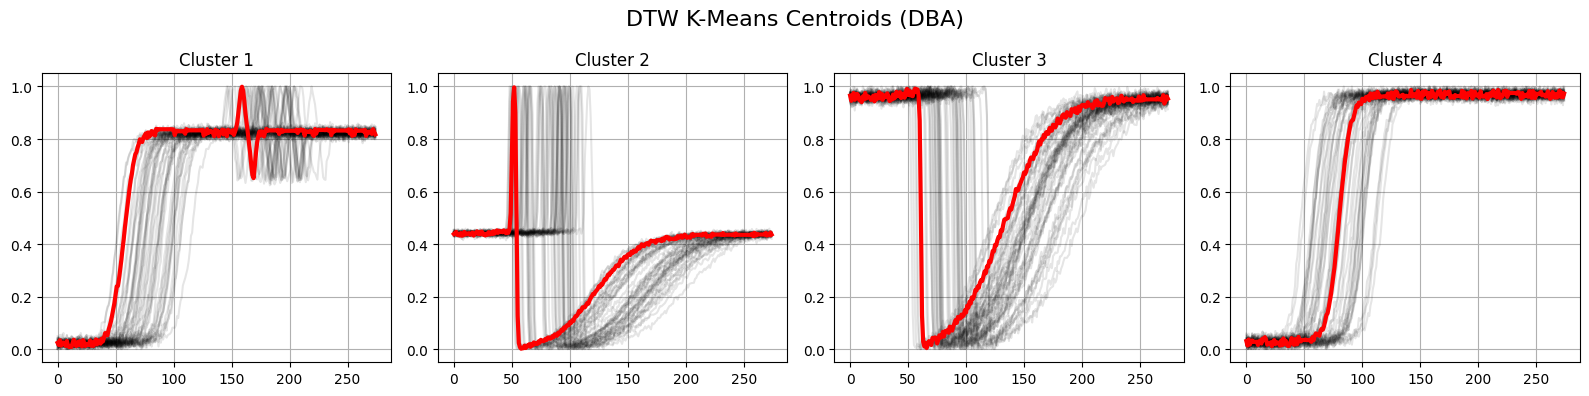

In [8]:
from tslearn.clustering import TimeSeriesKMeans
from tslearn.datasets import UCR_UEA_datasets
from tslearn.preprocessing import TimeSeriesScalerMinMax

# 1. Load and combine Train/Test for clustering
X_train, y_train, X_test, y_test = UCR_UEA_datasets().load_dataset("Trace")
X = np.concatenate((X_train, X_test))
X = TimeSeriesScalerMinMax().fit_transform(X)

n_clusters = 4

# 2. Euclidean K-Means
print("Running Euclidean K-Means...")
km_euc = TimeSeriesKMeans(n_clusters=n_clusters, metric="euclidean", random_state=42)
y_pred_euc = km_euc.fit_predict(X)

# 3. DTW K-Means
print("Running DTW K-Means (this may take a moment)...")
km_dtw = TimeSeriesKMeans(n_clusters=n_clusters, metric="dtw", random_state=42)
y_pred_dtw = km_dtw.fit_predict(X)

# 4. Visualization Function
def plot_clusters(model, predictions, data, title):
    plt.figure(figsize=(16, 4))
    for i in range(n_clusters):
        plt.subplot(1, n_clusters, i + 1)
        # Plot members of the cluster
        for series in data[predictions == i]:
            plt.plot(series.ravel(), "k-", alpha=0.1)
        # Plot the centroid
        plt.plot(model.cluster_centers_[i].ravel(), "r-", linewidth=3)
        plt.title(f"Cluster {i+1}")
        plt.grid(True)
    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

plot_clusters(km_euc, y_pred_euc, X, "Euclidean K-Means Centroids")
plot_clusters(km_dtw, y_pred_dtw, X, "DTW K-Means Centroids (DBA)")

---

#### Exercise 4: Time series prediction 
GunPoint dataset, use the 100 first values of a series to predict the 50 last ones with 2 different techniques:
 - MLP with classical MSE loss
 - MLP with soft-DTW loss (available in TS learn)
You have to use Pytorch implementation of MLP to be able to easily use a soft-DTW loss inside your MLP

In [7]:
import torch
import torch.nn as nn
from tslearn.metrics import SoftDTWLossPyTorch
from tslearn.datasets import UCR_UEA_datasets
from tslearn.preprocessing import TimeSeriesScalerMinMax

# 1. Prepare Data
X_train, y_train, X_test, y_test = UCR_UEA_datasets().load_dataset("GunPoint")
X = TimeSeriesScalerMinMax().fit_transform(np.concatenate((X_train, X_test)))

# Split into input (first 100 points) and target (last 50 points)
X_in = torch.tensor(X[:, :100, 0], dtype=torch.float32)
y_out = torch.tensor(X[:, 100:, 0], dtype=torch.float32)

# 2. Define MLP Model
class TimeSeriesMLP(nn.Module):
    def __init__(self):
        super(TimeSeriesMLP, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(100, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 50)
        )
    def forward(self, x):
        return self.net(x)

# 3. Training Function
def train_model(loss_type="mse"):
    model = TimeSeriesMLP()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    
    if loss_type == "mse":
        criterion = nn.MSELoss()
    else:
        # Soft-DTW requires a gamma smoothing parameter
        criterion = SoftDTWLossPyTorch(gamma=0.1)
    
    for epoch in range(200):
        optimizer.zero_grad()
        preds = model(X_in)
        
        # Soft-DTW expects (batch, sz, d)
        if loss_type == "soft-dtw":
            loss = criterion(preds.unsqueeze(-1), y_out.unsqueeze(-1)).mean()
        else:
            loss = criterion(preds, y_out)
            
        loss.backward()
        optimizer.step()
    return model

# Train both versions
model_mse = train_model(loss_type="mse")
model_sdtw = train_model(loss_type="soft-dtw")

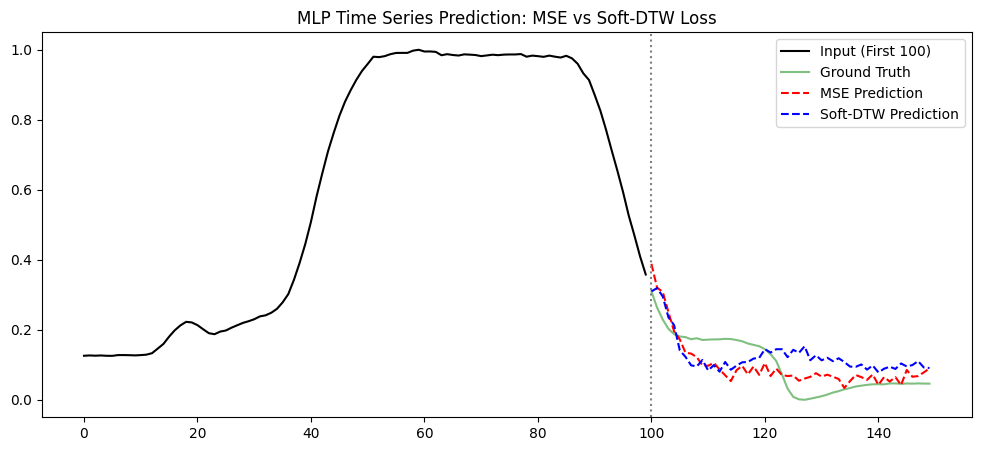

In [8]:
idx = 10 # Example test sample
with torch.no_grad():
    pred_mse = model_mse(X_in[idx:idx+1]).numpy().flatten()
    pred_sdtw = model_sdtw(X_in[idx:idx+1]).numpy().flatten()

plt.figure(figsize=(12, 5))
plt.plot(range(100), X_in[idx], 'k-', label="Input (First 100)")
plt.plot(range(100, 150), y_out[idx], 'g-', alpha=0.5, label="Ground Truth")
plt.plot(range(100, 150), pred_mse, 'r--', label="MSE Prediction")
plt.plot(range(100, 150), pred_sdtw, 'b--', label="Soft-DTW Prediction")
plt.axvline(x=100, color='gray', linestyle=':')
plt.title("MLP Time Series Prediction: MSE vs Soft-DTW Loss")
plt.legend()
plt.show()